# Chapitre 3 - Cours 5 : Transactionnel ou analytique, et le stockage en colonnes

Ce notebook couvre la seconde moitié du chapitre : la section *Transaction Processing or
Analytics?* (*Data Warehousing*, *The divergence between OLTP databases and data
warehouses*, *Stars and Snowflakes: Schemas for Analytics*), la section *Column-Oriented
Storage* (*Column Compression*, *Memory bandwidth and vectorized processing*, *Sort
Order in Column Storage*, *Several different sort orders*, *Writing to Column-Oriented
Storage*) et la section *Aggregation: Data Cubes and Materialized Views*.

**Plan.**

1. Transactionnel ou analytique ? Les entrepôts de données et l'ETL.
2. Étoiles et flocons : les schémas pour l'analytique.
3. Le stockage orienté colonnes.
4. La compression des colonnes : dictionnaire, bitmaps, codage par plages.
5. Bande passante mémoire et traitement vectorisé.
6. L'ordre de tri dans un stockage en colonnes.
7. Écrire dans un stockage en colonnes.
8. Agrégation : vues matérialisées et cubes de données.

In [1]:
import gc
import time

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from ddia import storage as S
from ddia.diagrams import Diagram
from ddia.plotting import (AMBER, COLORS, GRAY, GREEN, INDIGO, LIGHT, ROSE, SKY, SLATE, TEAL, VIOLET,
                           annotate_bars, finish, set_style, subtitle)
from ddia.timelines import SpaceTime

set_style()
plt.rcParams["axes.titlepad"] = 16
pd.set_option("display.precision", 3)
fact, dim_product, dim_date, dim_store = S.make_sales(500_000, n_extra_cols=12, seed=0)


def meilleur_temps(f, rep=5):
    """Meilleur temps (s) de `rep` exécutions, ramasse-miettes désactivé."""
    best = float("inf")
    for _ in range(rep):
        gc.disable()
        t0 = time.perf_counter()
        f()
        best = min(best, time.perf_counter() - t0)
        gc.enable()
    return best

## 1. Transactionnel ou analytique ? (section *Transaction Processing or Analytics?*)

Aux débuts des bases de données, une écriture correspondait à une **transaction
commerciale** (une vente, une commande, un salaire versé). Le mot est resté, même quand
les bases ont servi à tout autre chose : le schéma d'accès typique d'une application,
quelques lectures et écritures de lignes retrouvées par clé, s'appelle le **traitement
transactionnel en ligne** (*OLTP*). Mais les bases servent aussi à l'**analytique** :
des requêtes qui parcourent un très grand nombre de lignes, ne lisent que quelques
colonnes et calculent des agrégats (chiffre d'affaires par magasin et par mois, effet
d'une promotion...). Elles alimentent les rapports de **business intelligence** ; on
parle d'**OLAP** (*online analytic processing*).

In [2]:
pd.DataFrame({
    "Transactionnel (OLTP)": ["peu d'enregistrements par requête, retrouvés par clé",
                              "écritures aléatoires, faible latence, venant des utilisateurs",
                              "utilisateur final, via une application web",
                              "état le plus récent des données",
                              "de quelques Go à quelques To"],
    "Analytique (OLAP)": ["agrégats sur un très grand nombre d'enregistrements",
                          "imports en masse (ETL) ou flux d'événements",
                          "analyste interne, aide à la décision",
                          "historique des événements au fil du temps",
                          "de quelques To à quelques Po"],
}, index=["lectures", "écritures", "utilisé par", "données représentées", "volume"])

,Transactionnel (OLTP),Analytique (OLAP)
lectures,"peu d'enregistrements par requête, retrouvés p...",agrégats sur un très grand nombre d'enregistre...
écritures,"écritures aléatoires, faible latence, venant d...",imports en masse (ETL) ou flux d'événements
utilisé par,"utilisateur final, via une application web","analyste interne, aide à la décision"
données représentées,état le plus récent des données,historique des événements au fil du temps
volume,de quelques Go à quelques To,de quelques To à quelques Po


**Les entrepôts de données** (section *Data Warehousing*). Une entreprise a souvent des
dizaines de systèmes OLTP (site marchand, caisses, stocks, logistique, RH), chacun géré
par son équipe et tenu à une faible latence. Les administrateurs rechignent à y laisser
passer des requêtes analytiques coûteuses, qui dégraderaient les transactions. On copie
donc les données dans une base à part, l'**entrepôt de données** (*data warehouse*), en
lecture seule pour les analystes. La copie se fait par un processus d'**ETL** :
*extraire* les données des bases OLTP (export périodique ou flux continu de mises à
jour), les *transformer* en un schéma adapté à l'analyse (nettoyage, jointures), puis
les *charger* dans l'entrepôt.

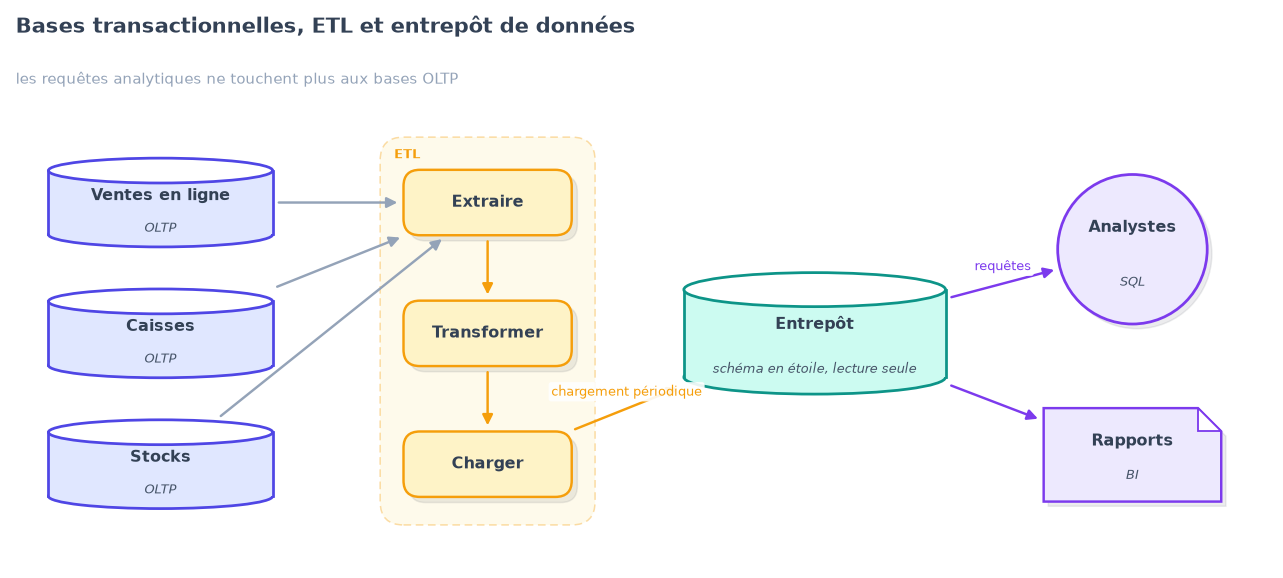

In [3]:
d = Diagram(13.5, 5.0, title="Bases transactionnelles, ETL et entrepôt de données",
            subtitle="les requêtes analytiques ne touchent plus aux bases OLTP")
for j, (nom, sub) in enumerate([("Ventes en ligne", "OLTP"), ("Caisses", "OLTP"), ("Stocks", "OLTP")]):
    d.box(f"o{j}", 1.6, 3.9 - j * 1.4, nom, sub=sub, color=INDIGO, kind="db", w=2.4, h=0.95)
d.box("e", 5.1, 3.9, "Extraire", color=AMBER, w=1.8, h=0.7)
d.box("t", 5.1, 2.5, "Transformer", color=AMBER, w=1.8, h=0.7)
d.box("l", 5.1, 1.1, "Charger", color=AMBER, w=1.8, h=0.7)
d.group(3.95, 0.45, 6.25, 4.6, "ETL", color=AMBER)
d.box("dw", 8.6, 2.5, "Entrepôt", sub="schéma en étoile, lecture seule", color=TEAL, kind="db", w=2.8, h=1.3)
d.box("bi", 12.0, 3.4, "Analystes", sub="SQL", color=VIOLET, kind="user", w=1.6)
d.box("rp", 12.0, 1.2, "Rapports", sub="BI", color=VIOLET, kind="doc", w=1.9, h=1.0)
for j in range(3):
    d.arrow(f"o{j}", "e", color=GRAY)
d.arrow("e", "t", color=AMBER); d.arrow("t", "l", color=AMBER)
d.arrow("l", "dw", "chargement périodique", color=AMBER)
d.arrow("dw", "bi", "requêtes", color=VIOLET); d.arrow("dw", "rp", color=VIOLET)
d.show()

**La divergence** (section *The divergence between OLTP databases and data
warehouses*). Le modèle de données d'un entrepôt est le plus souvent relationnel, car
SQL convient bien aux requêtes analytiques. En surface, entrepôt et base OLTP se
ressemblent donc (tous deux parlent SQL), mais leurs moteurs sont optimisés pour des
requêtes très différentes, et la plupart des éditeurs se spécialisent dans l'un ou
l'autre. C'est le sujet de la suite de ce cours : les index des cours 1 à 4 visent
l'OLTP, le stockage en colonnes vise l'analytique.

> **À retenir.** OLTP : beaucoup de petites requêtes par clé, sur l'état courant. OLAP :
> peu de grosses requêtes d'agrégation, sur l'historique. L'entrepôt de données, nourri
> par l'ETL, isole l'analytique des bases transactionnelles.

## 2. Étoiles et flocons (section *Stars and Snowflakes: Schemas for Analytics*)

Les entrepôts suivent souvent un **schéma en étoile** (modélisation dimensionnelle). Au
centre, une **table de faits** : chaque ligne est un événement (ici, l'achat d'un
produit par un client). Elle est **immense** (des milliards de lignes) et souvent
**large** (plus de cent colonnes). Certaines colonnes sont des mesures (quantité, prix),
les autres des **clés étrangères** vers des **tables de dimensions** qui répondent aux
questions qui, quoi, où, quand, comment, pourquoi : produit, magasin, date (même la date
est une dimension, pour pouvoir y attacher jours fériés et promotions), client,
promotion. Une variante, le **schéma en flocon**, normalise davantage les dimensions
(les marques et catégories dans leurs propres tables) : plus propre, moins pratique pour
les analystes.

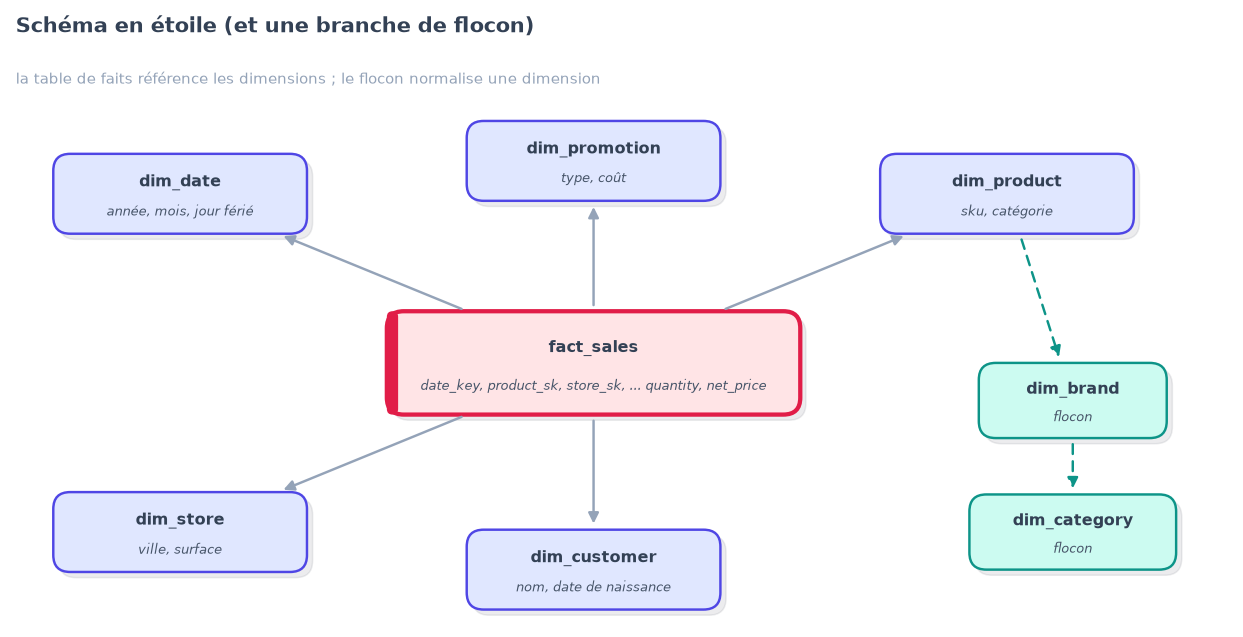

In [4]:
d = Diagram(13, 5.6, title="Schéma en étoile (et une branche de flocon)",
            subtitle="la table de faits référence les dimensions ; le flocon normalise une dimension")
d.box("f", 6.2, 2.8, "fact_sales", sub="date_key, product_sk, store_sk, ... quantity, net_price",
      color=ROSE, w=4.4, h=1.1, kind="model")
dims = [("dd", 1.8, 4.6, "dim_date", "année, mois, jour férié"), ("dp", 10.6, 4.6, "dim_product", "sku, catégorie"),
        ("ds", 1.8, 1.0, "dim_store", "ville, surface"), ("dc", 6.2, 0.6, "dim_customer", "nom, date de naissance"),
        ("dpr", 6.2, 4.95, "dim_promotion", "type, coût")]
for name, x, y, t, sub in dims:
    d.box(name, x, y, t, sub=sub, color=INDIGO, w=2.7, h=0.85)
    d.arrow("f", name, color=GRAY)
d.box("db", 11.3, 2.4, "dim_brand", sub="flocon", color=TEAL, w=2.0, h=0.8)
d.box("dcat", 11.3, 1.0, "dim_category", sub="flocon", color=TEAL, w=2.2, h=0.8)
d.arrow("dp", "db", color=TEAL, style="dashed")
d.arrow("db", "dcat", color=TEAL, style="dashed")
d.show()

Notre jeu de données synthétique (`S.make_sales`) suit ce schéma : 500 000 ventes sur
une année, 500 produits, 40 magasins, et 12 colonnes supplémentaires qui imitent la
largeur des vraies tables de faits.

In [5]:
print(f"fact_sales : {fact.shape[0]} lignes x {fact.shape[1]} colonnes ; dim_product : {len(dim_product)} ;",
      f"dim_date : {len(dim_date)} ; dim_store : {len(dim_store)}")
fact.head(3).iloc[:, :9]

fact_sales : 500000 lignes x 20 colonnes ; dim_product : 500 ; dim_date : 365 ; dim_store : 40


,date_key,product_sk,store_sk,promotion_sk,customer_sk,quantity,net_price,discount_price,attr_00
0,0,487,22,2,10633,3,5.73,5.16,99
1,0,61,25,0,14994,1,2.95,2.95,592
2,0,323,19,0,18479,1,3.04,3.04,789


> **À retenir.** Schéma en étoile : une table de faits immense et large au centre, des
> tables de dimensions autour. Le flocon normalise les dimensions en sous-tables.

## 3. Le stockage orienté colonnes (section *Column-Oriented Storage*)

**La requête type.** Les achats de fruits frais et de confiseries varient-ils selon le
jour de la semaine ? La requête lit **beaucoup de lignes** (toutes les ventes de
l'année) mais **trois colonnes** seulement de la table de faits : `date_key`,
`product_sk`, `quantity`.

```sql
SELECT dim_date.weekday, dim_product.category, SUM(fact_sales.quantity)
FROM fact_sales
  JOIN dim_date    ON fact_sales.date_key   = dim_date.date_key
  JOIN dim_product ON fact_sales.product_sk = dim_product.product_sk
WHERE dim_product.category IN ('Fruits frais', 'Confiserie')
GROUP BY dim_date.weekday, dim_product.category;
```

**Le problème du stockage en lignes.** Dans une base OLTP, les valeurs d'une ligne sont
rangées côte à côte (comme dans le CSV du cours 1). Même avec un index, le moteur doit
charger des lignes entières (ici 20 colonnes, souvent plus de cent), les décoder, puis
jeter presque tout. **L'idée du stockage en colonnes** : ranger ensemble toutes les
valeurs d'une **même colonne**. Une requête ne lit que les colonnes dont elle a besoin.
Chaque colonne garde les lignes **dans le même ordre** : la 23e valeur de chaque colonne
forme la 23e ligne.

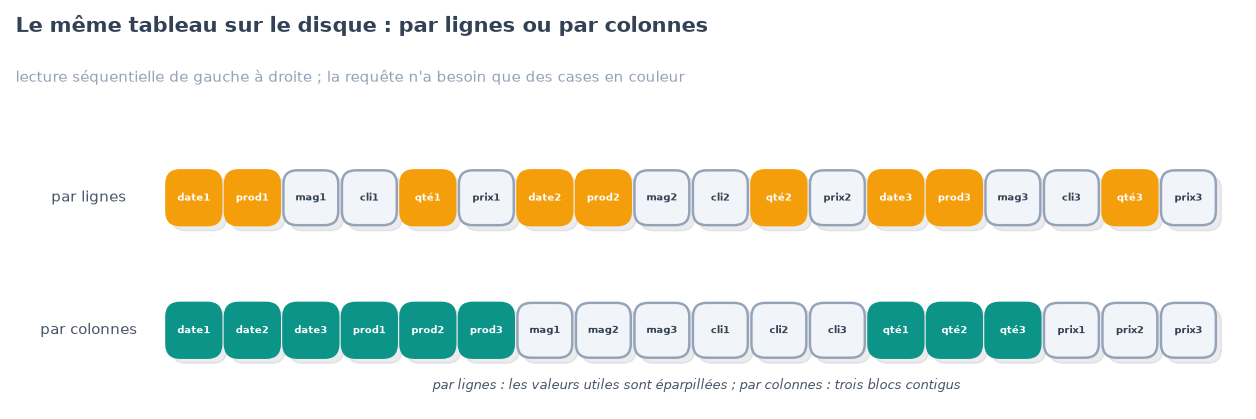

In [6]:
d = Diagram(13.5, 3.4, title="Le même tableau sur le disque : par lignes ou par colonnes",
            subtitle="lecture séquentielle de gauche à droite ; la requête n'a besoin que des cases en couleur")
noms = ["date", "prod", "mag", "cli", "qté", "prix"]
utiles = {"date", "prod", "qté"}
ordre_lignes = [(n_, r) for r in range(1, 4) for n_ in noms]
ordre_cols = [(n_, r) for n_ in noms for r in range(1, 4)]
for y, (titre, seq, coul) in enumerate([("par lignes", ordre_lignes, AMBER), ("par colonnes", ordre_cols, TEAL)]):
    yy = 2.3 - y * 1.45
    d.note(0.85, yy, titre, ha="center", style="normal", fontsize=9.5)
    for k, (n_, r) in enumerate(seq):
        d.box(f"{y}_{k}", 2.0 + k * 0.64, yy, f"{n_}{r}", color=coul if n_ in utiles else GRAY, w=0.6, h=0.6,
              fontsize=6.5, filled=n_ in utiles)
d.note(7.5, 0.25, "par lignes : les valeurs utiles sont éparpillées ; par colonnes : trois blocs contigus",
       fontsize=8.5)
d.show()

**Mesurons.** On range la table de faits de deux façons en mémoire : un tableau
structuré numpy, où chaque ligne occupe 160 octets contigus (20 colonnes de 8 octets),
et des colonnes séparées. Puis on calcule la somme des quantités par catégorie pour
deux catégories.

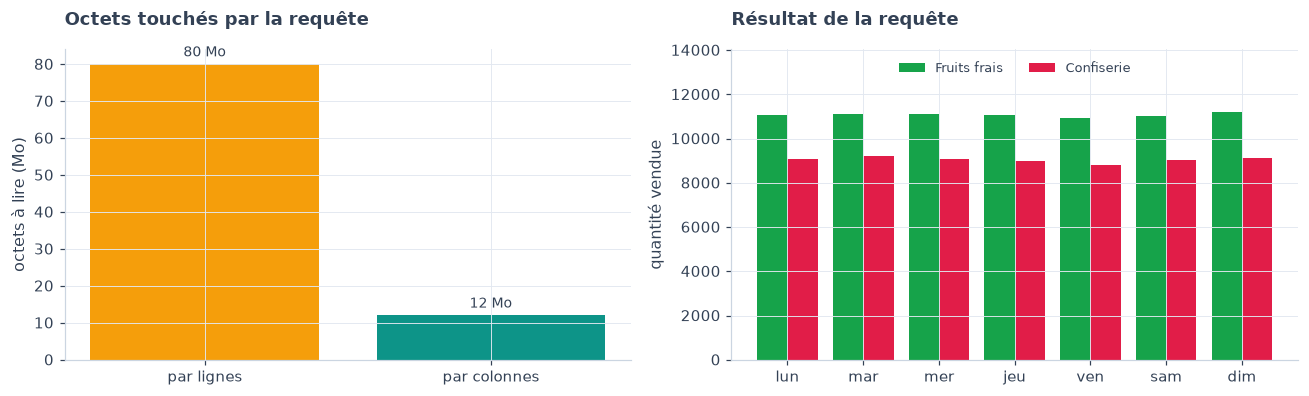

temps de la requête : 5.2 ms en lignes, 3.6 ms en colonnes


In [7]:
lignes = np.empty(len(fact), dtype=[(c, fact[c].dtype) for c in fact.columns])
for c in fact.columns:
    lignes[c] = fact[c].to_numpy()
colonnes = {c: np.ascontiguousarray(fact[c].to_numpy()) for c in fact.columns}
cat_of = dim_product.set_index("product_sk")["category"].to_numpy()
cible = np.isin(cat_of, ["Fruits frais", "Confiserie"])
wd = (dim_date["date"].to_numpy().astype("datetime64[D]").astype(np.int64) + 3) % 7  # lundi = 0


def requete(prod, date, qty):
    m = cible[prod]
    return np.bincount(wd[date[m]] * 2 + (cat_of[prod[m]] == "Confiserie"), weights=qty[m], minlength=14)


t_lignes = meilleur_temps(lambda: requete(lignes["product_sk"], lignes["date_key"], lignes["quantity"]))
t_cols = meilleur_temps(lambda: requete(colonnes["product_sk"], colonnes["date_key"], colonnes["quantity"]))
octets_lignes = lignes.nbytes
octets_cols = sum(colonnes[c].nbytes for c in ["product_sk", "date_key", "quantity"])
res = requete(colonnes["product_sk"], colonnes["date_key"], colonnes["quantity"]).reshape(7, 2)
fig, axes = plt.subplots(1, 2, figsize=(12, 3.7))
ax = axes[0]
ax.bar(["par lignes", "par colonnes"], [octets_lignes / 1e6, octets_cols / 1e6], color=[AMBER, TEAL])
annotate_bars(ax, "{:.0f} Mo")
ax.set_ylabel("octets à lire (Mo)"); ax.set_title("Octets touchés par la requête")
ax = axes[1]
jours = ["lun", "mar", "mer", "jeu", "ven", "sam", "dim"]
ax.bar(np.arange(7) - 0.2, res[:, 0], 0.4, color=GREEN, label="Fruits frais")
ax.bar(np.arange(7) + 0.2, res[:, 1], 0.4, color=ROSE, label="Confiserie")
ax.set_xticks(range(7), jours); ax.set_ylabel("quantité vendue")
ax.set_title("Résultat de la requête"); ax.set_ylim(0, res.max() * 1.25)
ax.legend(fontsize=8.5, loc="upper center", ncol=2)
finish(fig)
plt.show()
print(f"temps de la requête : {t_lignes * 1e3:.1f} ms en lignes, {t_cols * 1e3:.1f} ms en colonnes")

La requête touche environ sept fois moins d'octets en colonnes (3 colonnes sur 20) et
s'exécute plus vite, même entièrement en mémoire : lire des valeurs espacées de 160
octets gaspille la bande passante mémoire (chaque ligne de cache de 64 octets ne
contient qu'une valeur utile). Sur disque, l'écart de volume se traduit directement en
temps d'E/S. (Les données synthétiques ne montrent pas d'effet du jour de la semaine :
c'est attendu, aucun n'a été simulé.)

En pratique, un moteur en colonnes ne range pas une colonne de mille milliards de
valeurs d'un seul tenant : il découpe la table en **blocs** de milliers ou de millions de
lignes et, dans chaque bloc, range chaque colonne séparément. Les blocs correspondent
souvent à des plages de dates, pour ne charger que ceux d'une période. Parquet est un format de fichier en colonnes de ce type, qui sait même ranger des documents imbriqués (à la manière de Dremel, de Google).

Ne confondez pas avec le modèle **à colonnes larges** (*wide-column*, Bigtable, HBase,
Cassandra) : malgré le nom, ces bases rangent ensemble toutes les valeurs d'une ligne.

> **À retenir.** Ranger par colonnes permet à une requête analytique de ne lire que les
> quelques colonnes qu'elle utilise sur une table très large : moins d'octets lus sur
> disque et en mémoire.

## 4. La compression des colonnes (section *Column Compression*)

Les colonnes sont très **répétitives** : une colonne de produits ne contient que 500
valeurs distinctes sur 500 000 lignes. Trois techniques, souvent combinées :

- **dictionnaire** : remplacer chaque valeur par un petit code entier
  ($\lceil \log_2 n \rceil$ bits pour $n$ valeurs distinctes) ;
- **bitmaps** : pour une colonne à $n$ valeurs distinctes, $n$ bitmaps (un bit par
  ligne : 1 si la ligne a cette valeur) ;
- **codage par plages** (*run-length encoding*, RLE) : les bitmaps sont **creux**
  (surtout des 0) ; on stocke les longueurs des plages successives de 0 et de 1. Des
  techniques comme les *roaring bitmaps* choisissent pour chaque morceau la
  représentation la plus compacte.

Voici le codage d'une petite colonne, dans l'esprit de la figure du livre.

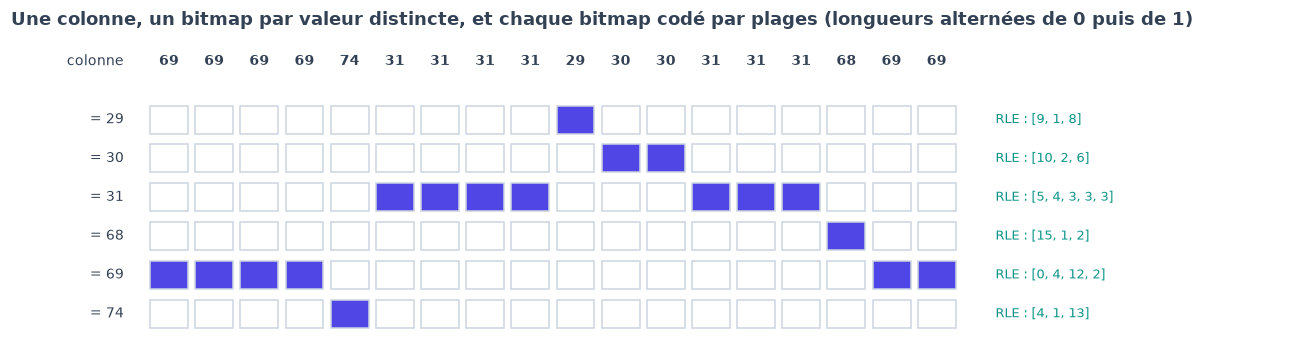

In [8]:
petite = np.array([69, 69, 69, 69, 74, 31, 31, 31, 31, 29, 30, 30, 31, 31, 31, 68, 69, 69])
bm = S.bitmap_index(petite)
fig, ax = plt.subplots(figsize=(12, 3.3))
ax.set_xlim(-3.5, len(petite) + 7); ax.set_ylim(-0.7, len(bm) + 1.2); ax.axis("off")
for j, v in enumerate(petite):
    ax.text(j, len(bm) + 0.5, str(v), ha="center", va="center", fontsize=9, fontweight="bold", color=SLATE)
ax.text(-1, len(bm) + 0.5, "colonne", ha="right", va="center", fontsize=9, color=SLATE)
for r, (val, bits) in enumerate(sorted(bm.items())):
    y = len(bm) - 1 - r
    ax.text(-1, y, f"= {val}", ha="right", va="center", fontsize=9, color=SLATE)
    for j, b in enumerate(bits):
        ax.add_patch(plt.Rectangle((j - 0.42, y - 0.36), 0.84, 0.72, facecolor=INDIGO if b else "white",
                                   edgecolor="#CBD5E1"))
    ax.text(len(petite) + 0.3, y, f"RLE : {S.bitmap_rle_runs(bits)}", va="center", fontsize=8.5, color=TEAL)
ax.set_title("Une colonne, un bitmap par valeur distincte, et chaque bitmap codé par plages "
             "(longueurs alternées de 0 puis de 1)", pad=6)
plt.tight_layout(); plt.show()

Sur notre table, comparons pour quelques colonnes la taille brute (8 octets par valeur),
le dictionnaire, et les bitmaps codés par plages (chaque longueur de plage codée en
varint). La table est dans l'ordre d'insertion, c'est-à-dire triée par date.

In [9]:
def tailles(colonne):
    vals, codes = S.dict_encode(colonne)
    brut = colonne.size * 8
    dico = colonne.size * S.bits_for(len(vals)) / 8 + vals.size * 8
    runs = sum(sum(S.varint_size(r) for r in S.bitmap_rle_runs(b)) for b in S.bitmap_index(codes).values())
    rle_val = S.rle_encode(colonne)[0].size * (8 + 4)
    return dict(distinctes=len(vals), brut_Mo=brut / 1e6, dictionnaire_Mo=dico / 1e6,
                bitmaps_RLE_Mo=runs / 1e6, RLE_direct_Mo=rle_val / 1e6)


comp = pd.DataFrame({c: tailles(fact[c].to_numpy()) for c in ["date_key", "store_sk", "promotion_sk",
                                                              "product_sk", "customer_sk"]}).T
comp

,distinctes,brut_Mo,dictionnaire_Mo,bitmaps_RLE_Mo,RLE_direct_Mo
date_key,365.0,4.0,0.565,0.003,0.004
store_sk,40.0,4.0,0.375,0.991,5.763
promotion_sk,12.0,4.0,0.250,0.287,1.647
product_sk,500.0,4.0,0.567,1.143,5.738
customer_sk,20000.0,4.0,1.097,1.758,6.000


- `date_key` (table triée par date) : 365 longues plages, la colonne se réduit à presque
  rien avec un RLE direct ;
- `store_sk` et `promotion_sk` (peu de valeurs distinctes) : le dictionnaire divise la
  taille par 10 à 20 (6 et 4 bits au lieu de 64) ;
- `product_sk` : 500 bitmaps très creux ; codés par plages, ils occupent pourtant plus
  que le dictionnaire, car dans une colonne non triée presque chaque ligne ouvre une
  nouvelle plage dans l'un des bitmaps. Le RLE devient imbattable quand la colonne est
  triée (section suivante sur l'ordre de tri) ;
- `customer_sk` (20 000 valeurs distinctes, presque toutes différentes d'une ligne à la
  suivante) : les bitmaps n'aident plus, le dictionnaire reste utile.

**Les bitmaps répondent directement aux filtres.** `WHERE product_sk IN (a, b, c)` : OU
des trois bitmaps. `WHERE product_sk = a AND store_sk = b` : ET de deux bitmaps (cela
marche parce que toutes les colonnes gardent le même ordre de lignes). Ces opérations
bit à bit sont extrêmement rapides.

In [10]:
bm_prod = S.bitmap_index(colonnes["product_sk"])
bm_store = S.bitmap_index(colonnes["store_sk"])
populaires = fact.product_sk.value_counts().index[:3].tolist()
ou = bm_prod[populaires[0]] | bm_prod[populaires[1]] | bm_prod[populaires[2]]
et = bm_prod[populaires[0]] & bm_store[3]
pd.DataFrame({"lignes sélectionnées": [int(ou.sum()), int(et.sum())],
              "vérification pandas": [int(fact.product_sk.isin(populaires).sum()),
                                      int(((fact.product_sk == populaires[0]) & (fact.store_sk == 3)).sum())]},
             index=[f"product_sk IN {tuple(populaires)}", f"product_sk = {populaires[0]} AND store_sk = 3"])

,lignes sélectionnées,vérification pandas
"product_sk IN (61, 489, 114)",151751,151751
product_sk = 61 AND store_sk = 3,1156,1156


> **À retenir.** Les colonnes se compressent très bien : dictionnaire pour les petites
> cardinalités, bitmaps codés par plages pour les colonnes creuses, RLE direct pour les
> colonnes triées. Les bitmaps servent aussi d'index pour les filtres (OU, ET).

## 5. Bande passante mémoire et traitement vectorisé (section *Memory bandwidth and vectorized processing*)

Pour une requête qui parcourt des millions de lignes, le goulot n'est pas seulement le
disque : c'est aussi la bande passante entre mémoire et cache du processeur, les
erreurs de prédiction de branchement et les bulles dans le pipeline d'instructions. Le
stockage en colonnes aide le processeur : un morceau de colonne compressée tient dans le
cache L1, et on le parcourt dans une **boucle serrée**, sans appel de fonction ; les
instructions **SIMD** traitent plusieurs valeurs par instruction. Des opérateurs comme le
ET de deux bitmaps travaillent directement sur les données compressées : c'est le
**traitement vectorisé**, par lots de valeurs plutôt que ligne par ligne.

**Mesurons** le filtre `produit = a ET magasin = b` puis la somme des quantités, de trois
façons : une boucle Python ligne par ligne (le pire des interpréteurs), des opérations
numpy sur colonnes entières (vectorisé, boucles en code natif), et le ET de bitmaps
précalculés.

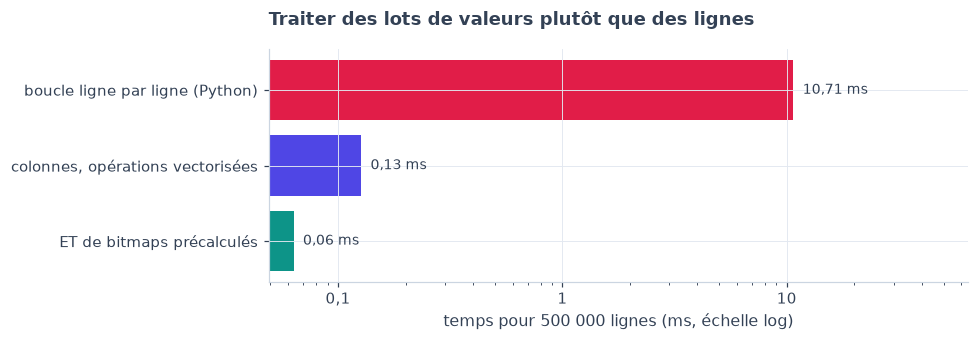

In [11]:
a_, b_ = populaires[0], 3
prod_l, store_l, qty_l = (colonnes[c][:100_000].tolist() for c in ["product_sk", "store_sk", "quantity"])


def boucle_python():
    total = 0
    for p, s, q in zip(prod_l, store_l, qty_l):
        if p == a_ and s == b_:
            total += q
    return total


qty = colonnes["quantity"]
t_py = meilleur_temps(boucle_python, rep=3) * len(qty) / 100_000  # extrapolé à 500 000 lignes
t_np = meilleur_temps(lambda: qty[(colonnes["product_sk"] == a_) & (colonnes["store_sk"] == b_)].sum())
t_bm = meilleur_temps(lambda: qty[bm_prod[a_] & bm_store[b_]].sum())
assert qty[bm_prod[a_] & bm_store[b_]].sum() == qty[(colonnes["product_sk"] == a_) & (colonnes["store_sk"] == b_)].sum()
vec = pd.Series({"boucle ligne par ligne (Python)": t_py, "colonnes, opérations vectorisées": t_np,
                 "ET de bitmaps précalculés": t_bm}) * 1e3
fig, ax = plt.subplots(figsize=(9, 3.2))
ax.barh(range(3), vec.values, color=[ROSE, INDIGO, TEAL])
ax.set_yticks(range(3), vec.index); ax.invert_yaxis()
ax.set_xscale("log"); S.plain_log_ticks(ax, "x")
for y, v in enumerate(vec.values):
    ax.text(v * 1.1, y, f"{v:.2f} ms".replace(".", ","), va="center", fontsize=9)
ax.set_xlim(right=vec.max() * 6)
ax.set_xlabel("temps pour 500 000 lignes (ms, échelle log)")
ax.set_title("Traiter des lots de valeurs plutôt que des lignes")
plt.tight_layout(); plt.show()

Près de deux ordres de grandeur séparent la boucle ligne par ligne des opérations
vectorisées. Une partie de l'écart vient de l'interprète Python lui-même, mais c'est
précisément le point : un moteur qui interprète la requête valeur par valeur paie un
surcoût par valeur, alors qu'un opérateur vectorisé l'amortit sur des milliers de
valeurs. Le ET de bitmaps précalculés évite même les comparaisons.

> **À retenir.** Le stockage en colonnes économise aussi le processeur : boucles serrées
> sur des données contiguës et compressées, SIMD, opérateurs appliqués par lots.

## 6. L'ordre de tri (section *Sort Order in Column Storage*)

L'ordre des lignes est libre : le plus simple est l'ordre d'insertion. Mais on peut
**trier** la table, comme une SSTable, et s'en servir comme d'un index. Attention : on
ne trie pas chaque colonne indépendamment (on ne saurait plus quelles valeurs forment une
ligne) ; on trie des **lignes entières**, rangées ensuite par colonnes.

- Si les requêtes portent souvent sur des plages de dates, `date_key` en **première clé
  de tri** permet de ne lire que les lignes du dernier mois.
- Une **deuxième clé** (par exemple `product_sk`) range ensemble les ventes d'un même
  produit le même jour.
- Bonus : la première clé de tri forme de **longues plages** de valeurs identiques, que
  le RLE compresse à l'extrême ; l'effet s'atténue pour les clés suivantes.

Mesurons la taille du RLE direct de chaque colonne pour trois ordres de tri.

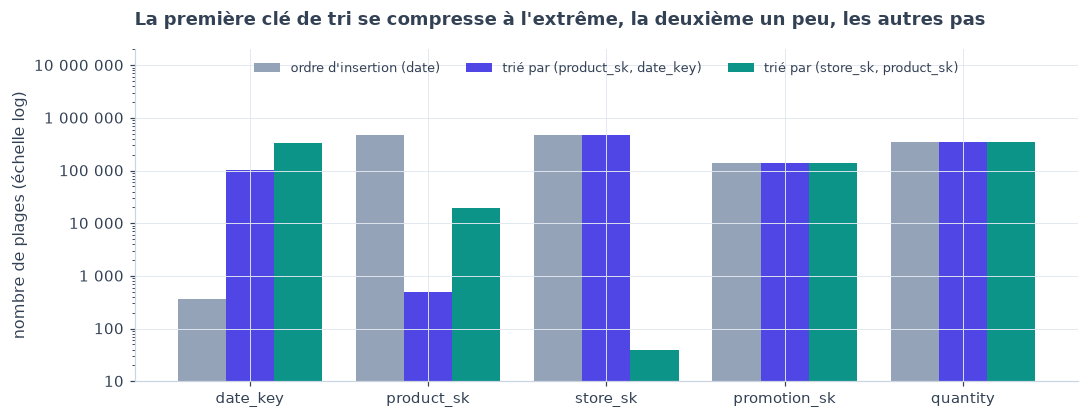

ordre,ordre d'insertion (date),"trié par (product_sk, date_key)","trié par (store_sk, product_sk)"
colonne,,,
date_key,365,104813,330986
product_sk,478159,500,19440
store_sk,480235,480589,40
promotion_sk,137266,136999,137100
quantity,355147,355164,355063


In [12]:
ordres = {"ordre d'insertion (date)": None, "trié par (product_sk, date_key)": ["product_sk", "date_key"],
          "trié par (store_sk, product_sk)": ["store_sk", "product_sk"]}
cols_mesurees = ["date_key", "product_sk", "store_sk", "promotion_sk", "quantity"]
rows = []
for nom, cles in ordres.items():
    t = fact if cles is None else fact.sort_values(cles, kind="stable")
    for c in cols_mesurees:
        rows.append(dict(ordre=nom, colonne=c, plages=S.rle_encode(t[c].to_numpy())[0].size))
tri = pd.DataFrame(rows).pivot(index="colonne", columns="ordre", values="plages").loc[cols_mesurees]
fig, ax = plt.subplots(figsize=(10, 3.9))
x = np.arange(len(tri))
for j, (nom, c) in enumerate(zip(ordres, [GRAY, INDIGO, TEAL])):
    ax.bar(x + (j - 1) * 0.27, tri[nom], 0.27, color=c, label=nom)
ax.set_yscale("log"); S.plain_log_ticks(ax)
ax.set_xticks(x, tri.index)
ax.set_ylabel("nombre de plages (échelle log)")
ax.set_title("La première clé de tri se compresse à l'extrême, la deuxième un peu, les autres pas")
ax.set_ylim(10, 2e7)
ax.legend(fontsize=8.5, loc="upper center", ncol=3)
plt.tight_layout(); plt.show()
tri

Triée par `(product_sk, date_key)`, la colonne `product_sk` ne compte plus que 500
plages (une par produit) ; `date_key`, deuxième clé, passe de 365 plages (elle était la
clé de tri implicite) à environ 105 000 : une par couple (produit, jour) présent. De même,
triée par `(store_sk, product_sk)`, la première clé n'a que 40 plages et la deuxième
environ 19 000. Les colonnes qui ne sont pas des clés de tri (`promotion_sk`,
`quantity`) ne gagnent rien : elles changent presque à chaque ligne.

**Plusieurs ordres de tri** (section *Several different sort orders*). Le système C-Store,
repris commercialement par Vertica, pousse l'idée plus loin : puisqu'il faut de toute
façon répliquer les données sur plusieurs machines, autant stocker chaque copie **triée
différemment**, et choisir pour chaque requête la copie dont l'ordre l'arrange le mieux.
C'est l'équivalent analytique de plusieurs index secondaires, à ceci près que chaque
copie contient toutes les données (pas de pointeur vers ailleurs).

> **À retenir.** Trier des lignes entières selon une ou deux clés choisies d'après les
> requêtes sert à la fois d'index (plages de dates) et de compression (longues plages
> de valeurs identiques sur la première clé).